# Exercise 4: Calibrate to an Experiment

Lab 24 shows that the national reference model's observational fit for Paid Search is loose, and that a simulated incrementality experiment sharpens it: added as an extra likelihood term, the experiment does not overrule the observational fit, it combines with it.
This exercise asks you to reproduce that calibration yourself: extend the reference model with an experiment likelihood term for Search, refit it, and check that Search's posterior narrows and shifts towards the experiment result.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from mmm_book import RANDOM_SEED
from mmm_book.plotting import mmm_style
from mmm_book.reference import REVENUE_SCALE, build_features, national_aggregate, reference_model
from mmm_book.sedge import GROUND_TRUTH, generate_sedge

mmm_style()

SAMPLE_KWARGS = dict(
    draws=1000,
    tune=1000,
    chains=4,
    cores=1,
    target_accept=0.95,
    random_seed=RANDOM_SEED,
    progressbar=False,
)


def check(idata):
    n_divergent = int(idata.sample_stats["diverging"].sum())
    r_hat = float(az.summary(idata, kind="diagnostics")["r_hat"].max())
    print(f"divergent transitions: {n_divergent}, largest r_hat: {r_hat:.3f}")

## Fitting the observational model

This reuses the shared national-aggregate reference model from `mmm_book.reference`, the model Lab 15 builds with the priors Lab 17 chooses.
Sampling uses the settings every lab uses (four chains of 1,000 draws after 1,000 warm-up steps, target acceptance 0.95), and the cell checks the fit samples cleanly before anything is read from it; Lab 18 shows what goes wrong with fewer, shorter chains.

In [2]:
df = generate_sedge()
nat = national_aggregate(df)
model = reference_model(nat)

with model:
    idata = pm.sample(**SAMPLE_KWARGS)
check(idata)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


divergent transitions: 0, largest r_hat: 1.004


## The observational estimate for Search

`implied_roas_draws` converts posterior draws of `beta_search` into Search's ROAS, using the Search feature's total and the total Search spend, the same calculation as Lab 23's recovery check and Lab 24.
It takes a fitted `idata` as an argument so it can be reused on the calibrated fit later.

In [3]:
feat = build_features(nat)
feat_search_total = float(feat["search"].sum())
spend_search_total = float(nat["search_spend"].to_numpy(dtype=float).sum())


def implied_roas_draws(idata_):
    """Posterior draws of Search's ROAS from any fit of this model."""
    beta_draws = idata_.posterior["beta_search"].to_numpy().reshape(-1)
    return beta_draws * feat_search_total * REVENUE_SCALE / spend_search_total


def describe(label, draws):
    lo, hi = np.percentile(draws, [5, 95])
    print(
        f"{label:<28}mean {draws.mean():.2f}, sd {draws.std():.2f}, "
        f"90% interval {lo:.2f} to {hi:.2f}"
    )


roas_search_obs = implied_roas_draws(idata)
describe("observational Search ROAS:", roas_search_obs)
print(f"ground truth Search ROAS:   {GROUND_TRUTH['search']:.2f}")

observational Search ROAS:  mean 3.10, sd 1.46, 90% interval 0.74 to 5.54
ground truth Search ROAS:   2.70


## Task

`experiment_roas` below simulates a noisy experiment reading of Search's true ROAS, with `experiment_se` its standard error; in a real analysis the truth would be unknown and only the noisy result would be seen.
The experiment is imagined to have run for eight weeks in the spring, while the model's ROAS averages three years, so the team has also recorded a transport judgement, `sigma_transport`, before seeing how the model responds (Chapter 24).
`model_calibrated` is the same reference model as `model` above, reopened with `with model_calibrated:` so you can add to it, the extension pattern Lab 24 uses.

Extend `model_calibrated` with an experiment likelihood term for Search:

- compute Chapter 24's widened standard deviation, `sigma_eff = sqrt(experiment_se**2 + sigma_transport**2)`
- build a deterministic named `implied_search_roas` that converts `model_calibrated["beta_search"]` into the same ROAS units as `implied_roas_draws`, that is `beta_search * feat_search_total * REVENUE_SCALE / spend_search_total`
- add a `pm.Normal` named `experiment_roas_obs`, with `mu` equal to that deterministic, `sigma=sigma_eff` and `observed=experiment_roas`

In [4]:
rng = np.random.default_rng(RANDOM_SEED)
experiment_se = 0.3
sigma_transport = 0.2
experiment_roas = float(GROUND_TRUTH["search"] + rng.normal(0, experiment_se))
print(
    f"simulated experiment result for Search ROAS: {experiment_roas:.2f} "
    f"(SE {experiment_se}, transport {sigma_transport})"
)

model_calibrated = reference_model(nat)
# YOUR CODE HERE: compute sigma_eff and extend model_calibrated with an experiment
# likelihood term for Search.
# Stub: adds nothing, so the calibrated model is identical to the observational one and
# the checks below will not pass yet.

simulated experiment result for Search ROAS: 2.79 (SE 0.3, transport 0.2)


## Refitting the calibrated model

The calibrated model is sampled with the same settings as the observational fit above.

In [5]:
with model_calibrated:
    idata_calibrated = pm.sample(**SAMPLE_KWARGS)
check(idata_calibrated)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


divergent transitions: 0, largest r_hat: 1.004


## Before and after calibration

Comparing the observational-only posterior for Search's ROAS with the calibrated one should show a shift towards the experiment result and a narrowing, because the experiment adds information the observational data alone did not have.

In [6]:
roas_search_calibrated = implied_roas_draws(idata_calibrated)

describe("observational Search ROAS:", roas_search_obs)
describe("calibrated Search ROAS:", roas_search_calibrated)
print(f"experiment result:          {experiment_roas:.2f}")
print(f"ground truth:               {GROUND_TRUTH['search']:.2f}")

observational Search ROAS:  mean 3.10, sd 1.46, 90% interval 0.74 to 5.54
calibrated Search ROAS:     mean 3.10, sd 1.46, 90% interval 0.74 to 5.54
experiment result:          2.79
ground truth:               2.70


## A look at the shift

This plots both posteriors against the experiment result and the ground truth, so you can see the shift and narrowing before running the self-check.

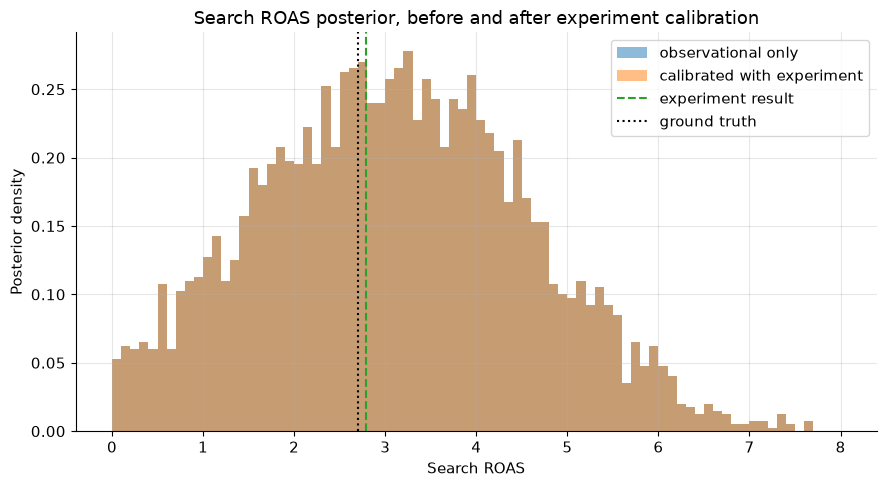

In [7]:
fig, ax = plt.subplots()
bins = np.linspace(0, 8, 81)
ax.hist(roas_search_obs, bins=bins, density=True, alpha=0.5, label="observational only")
ax.hist(
    roas_search_calibrated, bins=bins, density=True, alpha=0.5, label="calibrated with experiment"
)
ax.axvline(experiment_roas, color="C2", linestyle="--", label="experiment result")
ax.axvline(GROUND_TRUTH["search"], color="k", linestyle=":", label="ground truth")
ax.set_xlabel("Search ROAS")
ax.set_ylabel("Posterior density")
ax.set_title("Search ROAS posterior, before and after experiment calibration")
ax.legend()
fig.tight_layout()

## Self-check

In [8]:
checks = {
    "the model has an experiment_roas_obs likelihood term": "experiment_roas_obs"
    in model_calibrated.named_vars,
    "calibrated posterior sd is tighter than the observational one": bool(
        roas_search_calibrated.std() < roas_search_obs.std()
    ),
    "calibrated posterior mean moved towards the experiment result": bool(
        abs(roas_search_calibrated.mean() - experiment_roas)
        < abs(roas_search_obs.mean() - experiment_roas)
    ),
}
for name, ok in checks.items():
    print(f"{name}: {'PASS' if ok else 'FAIL'}")
print("Self-check: PASS" if all(checks.values()) else "Self-check: FAIL")

the model has an experiment_roas_obs likelihood term: FAIL
calibrated posterior sd is tighter than the observational one: FAIL
calibrated posterior mean moved towards the experiment result: FAIL
Self-check: FAIL
